## Compressing and Representing Information

+ ZIP JPEG等传统压缩方法针对特定数据类型，采用人工设计的算法减小文件体积。这类方法虽然在其目标场景下效果良好，但**缺少**学习型压缩技术所具备的灵活性与自适应能力。
+ 例如，ZIP通过识别并编码重复模式，擅长对通用数据进行无损压缩。
+ 而JPEG专门用于图像压缩，通过舍弃人眼不易察觉的视觉信息，实现大幅度的体积缩减。
+ 但这些传统方法**无法从被压缩的数据中学习**，不能自动适配不同类型的内容，也无法针对除文件瘦身之外的特定任务做优化。这正是机器学习模型可以发挥作用的地方。

+ 如果我们的系统训练得当，并且解码器能够从表征中还原原始数据，就说明学习得到的表征已经捕获了核心信息。因此，对表征进行操作等价于直接处理原始数据，但所需的**内存与计算量要小得多**。这是Stable Diffusion这类模型的核心设计思路之一
+ 由于学习得到的表征捕获了核心信息，我们可以在自编码器训练完成后，将编码器与解码器拆分开来，并把编码器用作特征提取组件。如图3-1中间面板所示，在编码器的输出之上叠加一个小型网络，就可以针对不同任务训练模型，例如文本分类或图像分类。
+ 这些小型网络并不直接处理整张输入图像，而是处理编码器提取出的核心特征。

In [1]:
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from matplotlib import pyplot as plt
from PIL import Image
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torchvision.transforms import Compose, Resize, ToTensor


## Dataset

在PyTorch中，数据集由一个普通Python类表示，该类需要继承自`Dataset`类。你可以把它理解成一个元组列表，每个元组对应一组样本（特征，标签）。
它必须实现的最核心方法有：
+ `__init__(self)`：该方法接收构建元组列表所需的各类参数。参数可以是待加载和处理的CSV文件名；也可以是两个张量，一个存放特征，另一个存放标签；或是其他任意形式，具体取决于当前任务。
+ `__getitem__(self, index)`：该方法让数据集支持索引访问，使其使用方式类似列表（`dataset[i]`），它必须返回对应样本的元组（特征，标签），我们既可以返回预先加载好的数据集中对应的切片，也可以像前面提到的那样按需加载数据。
+ `__len__(self)`：该方法直接返回整个数据集的样本总量，这样在采样时，索引取值范围就不会超出数据集的实际大小。
+ **不需要在构造方法（`__init__()`）中加载整个数据集**。如果你的数据集很大（例如包含数万张图像文件），一次性全部加载会造成内存利用率低下。推荐采用按需加载的方式（每当调用`__getitem__()`时再读取数据）。


In [2]:
class ImageFile(Dataset):
    def __init__(self, image_path, transform=None):
        self.image_path = Path(image_path)
        self.transform = transform
        image_extensions = ("*.jpg", "*.jpeg", "*.png", "*.gif")
        self.image_files = [
            file for ext in image_extensions for file in self.image_path.glob(ext)
        ]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_file = self.image_files[idx]
        image = Image.open(image_file).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, image

In [3]:
transform = Compose(
    [
        Resize((64, 64)),
        ToTensor(),
        lambda x: 2 * x - 1  # [0,1] → [-1,1]，匹配tanh 
    ]
)
image_path = "../Datasets/images"

In [4]:
ImageDataset = ImageFile(image_path=image_path, transform=transform)
train_loader = DataLoader(ImageDataset, batch_size=256, shuffle=True)

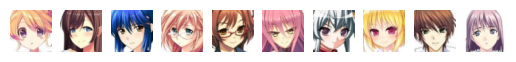

In [5]:
fig, ax = plt.subplots(1, 10)
for i in range(10):
    train = (ImageDataset[i][0].permute(1, 2, 0).numpy()+1)/2  # [-1,1] → [0,1]
    ax[i].imshow(train)
    ax[i].axis("off")

**输入图像维度**：假设输入图像的维度为$W\times H\times C$，其中$W$是图像的宽度，$H$是图像的高度，$C$是图像的通道数。
- **卷积核维度**：设卷积核的大小为$K\times K$，卷积核的数量为$N$（即输出通道数）。
- **填充（Padding）**：通常用$P$表示在图像周围填充的像素数。如果是对称填充，那么在宽度和高度方向上都分别填充$P$个像素。
- **步幅（Stride）**：用$S$表示，它指的是卷积核在图像上滑动的步长。


经过卷积操作后，输出特征图的维度计算公式如下：

- **输出宽度**：$ W_{out}=\lfloor\frac{W + 2P - K}{S}\rfloor + 1 $
- **输出高度**：$ H_{out}=\lfloor\frac{H + 2P - K}{S}\rfloor + 1 $
- **输出通道数**：$ C_{out}=N $


In [6]:
class Encoder(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()
        self.con_block = nn.Sequential(
            # 3@64x64 -> 64@32x32
            nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(64),
            # 64@32x32 -> 128@16x16
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(128),
            # 128@16x16 -> 256@8x8
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(256),
            # 256@8x8 -> 512@4x4
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(512),
            # 512@4x4 -> 1024@1x1
            nn.Conv2d(512, 1024, kernel_size=4, stride=2, padding=0),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(1024),
        )
        self.fc_block = nn.Sequential(
            nn.Linear(1024, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
        )

    def forward(self, x):
        x = self.con_block(x)
        # shape: (batch_size, 1024, 1, 1)
        x = x.flatten(start_dim=1)
        # shape: (batch_size, 1024)
        x = self.fc_block(x)
        # shape: (batch_size, 256)
        return x

反卷积（也称为转置卷积）是卷积的逆操作，其维度变化公式与卷积类似，但计算方式略有不同。以下是二维反卷积的维度变化公式：
- **输入特征图维度**：假设输入特征图的维度为\(W\times H\times C\)，其中\(W\)是特征图的宽度，\(H\)是特征图的高度，\(C\)是特征图的通道数。
- **卷积核维度**：设卷积核的大小为\(K\times K\)，卷积核的数量为\(N\)（即输出通道数）。
- **填充（Padding）**：通常用\(P\)表示在特征图周围填充的像素数。如果是对称填充，那么在宽度和高度方向上都分别填充\(P\)个像素。需要注意的是，在反卷积中，填充的效果与卷积相反，它会减少输出的尺寸。
- **步幅（Stride）**：用\(S\)表示，它指的是卷积核在特征图上滑动的步长。

经过反卷积操作后，输出图像的维度计算公式如下：

- **输出宽度**：$W_{out}=(W - 1)\times S - 2P + K$
- **输出高度**：$H_{out}=(H - 1)\times S - 2P + K$
- **输出通道数**：$C_{out}=N$


In [7]:
class Decoder(nn.Module):
    def __init__(self, out_channels=3):
        super().__init__()
        self.fc_block = nn.Sequential(
            # shape: (batch_size, 256) -> (batch_size, 512)
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            # shape: (batch_size, 512) -> (batch_size, 1024)
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
        )
        self.con_block = nn.Sequential(
            # 1024@1x1 -> 512@4x4
            nn.ConvTranspose2d(1024, 512, kernel_size=4, stride=1, padding=0),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(512),
            # 512@4x4 -> 256@8x8
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(256),
            # 256@8x8 -> 128@16x16
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(128),
            # 128@16x16 -> 64@32x32
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.BatchNorm2d(64),
            # 64@32x32 -> 3@64x64
            nn.ConvTranspose2d(64, out_channels, kernel_size=4, stride=2, padding=1),
        )

    def forward(self, x):
        x = self.fc_block(x)
        # shape: (batch_size, 1024)
        x = x.view(-1, 1024, 1, 1)
        # shape: (batch_size, 1024, 1, 1)
        x = self.con_block(x)
        # shape: (batch_size, out_channels, 64, 64)
        return F.tanh(x)


In [8]:
class AutoEncoder(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        self.encoder = Encoder(in_channels=in_channels)
        self.decoder = Decoder(out_channels=out_channels)

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

In [9]:
class SSIM_MSE_Loss(nn.Module):
    def __init__(self, ssim_weight=0.8, mse_weight=0.2):
        super().__init__()
        self.ssim = StructuralSimilarityIndexMeasure(data_range=1.0)
        self.MSE = nn.MSELoss()
        self.ssim_weight = ssim_weight
        self.mse_weight = mse_weight

    def forward(self, x, y):
        ssim_loss = 1 - self.ssim(x, y)
        mse_loss = self.MSE(x, y)
        return self.ssim_weight * ssim_loss + self.mse_weight * mse_loss

In [10]:
def mini_batch_train(data_loader, model, optimizer, loss_fn, device="cuda"):
    mini_batch_losses = []
    for x_batch, y_batch in data_loader:
        # 将数据放到GPU上
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        # 置为训练状态
        model.train()
        # Step 1 - 前向计算预测值
        yhat = model(x_batch)
        # Step 2 - 计算损失
        mini_batch_loss = loss_fn(yhat, y_batch)
        # Step 3 - 计算梯度
        mini_batch_loss.backward()
        # Step 4 - 参数更新
        optimizer.step()
        optimizer.zero_grad()

        mini_batch_losses.append(mini_batch_loss.item())

    loss = np.mean(mini_batch_losses)
    return loss

In [11]:
def train(model, train_loader, loss_fn, optimizer, epochs, device="cuda"):
    model.to(device)
    loss_fn.to(device)
    # 循环轮数计数
    losses = []  # 每轮训练的损失
    for total_epoch, epoch in enumerate(range(epochs)):
        model.train()
        
        # 进入mini-batch的内循环
        loss = mini_batch_train(train_loader, model, optimizer, loss_fn, device)
        losses.append(loss)
        print(f"Epoch {total_epoch}/{epochs}, Loss: {loss:.4f}")

    return losses

In [13]:
epochs = 50
lr = 1e-3
model = AutoEncoder(in_channels=3, out_channels=3)
optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
loss_fn = SSIM_MSE_Loss()
device = "cuda" if torch.cuda.is_available() else "cpu"

In [14]:
train_losses = train(
    model, train_loader, loss_fn, optimizer, epochs, device=device
)

Epoch 0/50, Loss: 0.7260
Epoch 1/50, Loss: 0.6729
Epoch 2/50, Loss: 0.6402
Epoch 3/50, Loss: 0.6172
Epoch 4/50, Loss: 0.6095
Epoch 5/50, Loss: 0.5920
Epoch 6/50, Loss: 0.5791
Epoch 7/50, Loss: 0.5666
Epoch 8/50, Loss: 0.5556
Epoch 9/50, Loss: 0.5440
Epoch 10/50, Loss: 0.5335
Epoch 11/50, Loss: 0.5225
Epoch 12/50, Loss: 0.5125
Epoch 13/50, Loss: 0.5077
Epoch 14/50, Loss: 0.4964
Epoch 15/50, Loss: 0.4865
Epoch 16/50, Loss: 0.4778
Epoch 17/50, Loss: 0.4718
Epoch 18/50, Loss: 0.4625
Epoch 19/50, Loss: 0.4565
Epoch 20/50, Loss: 0.4490
Epoch 21/50, Loss: 0.4436
Epoch 22/50, Loss: 0.4366
Epoch 23/50, Loss: 0.4365
Epoch 24/50, Loss: 0.4263
Epoch 25/50, Loss: 0.4207
Epoch 26/50, Loss: 0.4150
Epoch 27/50, Loss: 0.4104
Epoch 28/50, Loss: 0.4115
Epoch 29/50, Loss: 0.4079
Epoch 30/50, Loss: 0.3989
Epoch 31/50, Loss: 0.3928
Epoch 32/50, Loss: 0.3901
Epoch 33/50, Loss: 0.3861
Epoch 34/50, Loss: 0.3825
Epoch 35/50, Loss: 0.3793
Epoch 36/50, Loss: 0.3758
Epoch 37/50, Loss: 0.3728
Epoch 38/50, Loss: 0.3

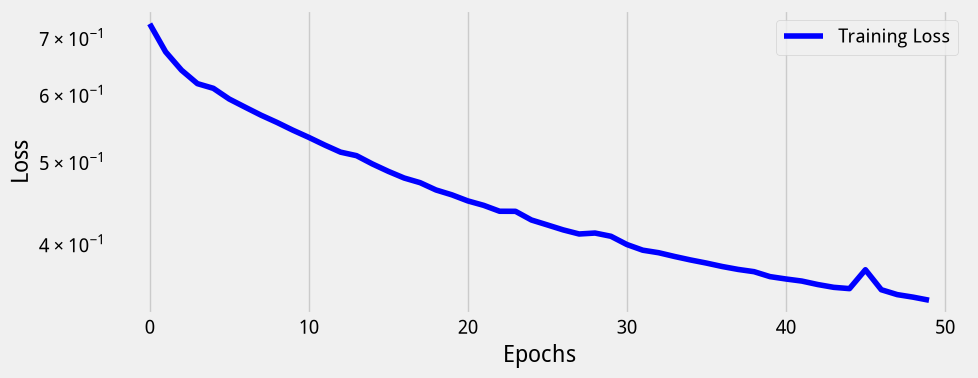

In [15]:
plt.style.use("fivethirtyeight")
def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Training Loss", c="b")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()

In [16]:
fake_image = torch.randn(10, 256).to(device)
with torch.inference_mode():
    reconstructed_image = model.decoder(fake_image)
images = reconstructed_image.detach().cpu().permute(0, 2, 3, 1).numpy()

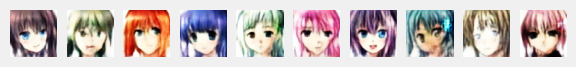

In [17]:
fig, ax = plt.subplots(1, 10)
for i in range(10):
    ax[i].imshow((images[i] + 1) / 2)
    ax[i].axis("off")


In [ ]:
# for i in range(5):
#     plt.imsave(f'./data/outputs/img_{i}.png', reconstructed_image[i].cpu().permute(1, 2, 0).numpy())